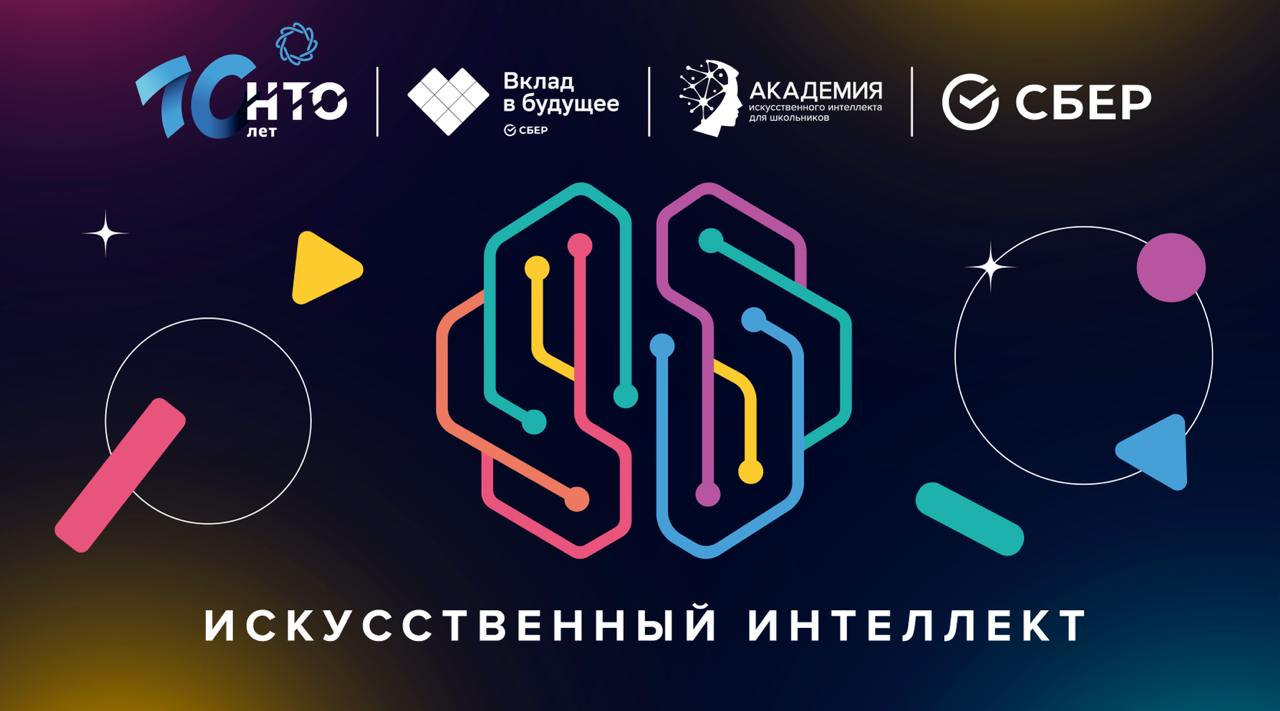

# Разбор baseline по классификации cложноразличимых видов животных по фотографии

Перед вами базовое решение, позволяющие обучить модель машинного обучения тому, какое животное находится на фотографии, а так же сформировать сабмит (посылку с решением) с результатами работы модели, чтобы можно было понять, насколько хорошо работает ваша модель.

Код ниже состоит из четырёх основных частей:
1. Установка и импорт библиотек, требуемых для работы
2. Подготовка данных для обучения модели ResNet18
3. Обучение базовой модели
5. Запуск модели и формирование сабмита.


При запуске jupyter-notebook с видеокартой нужно заменить runtime type.
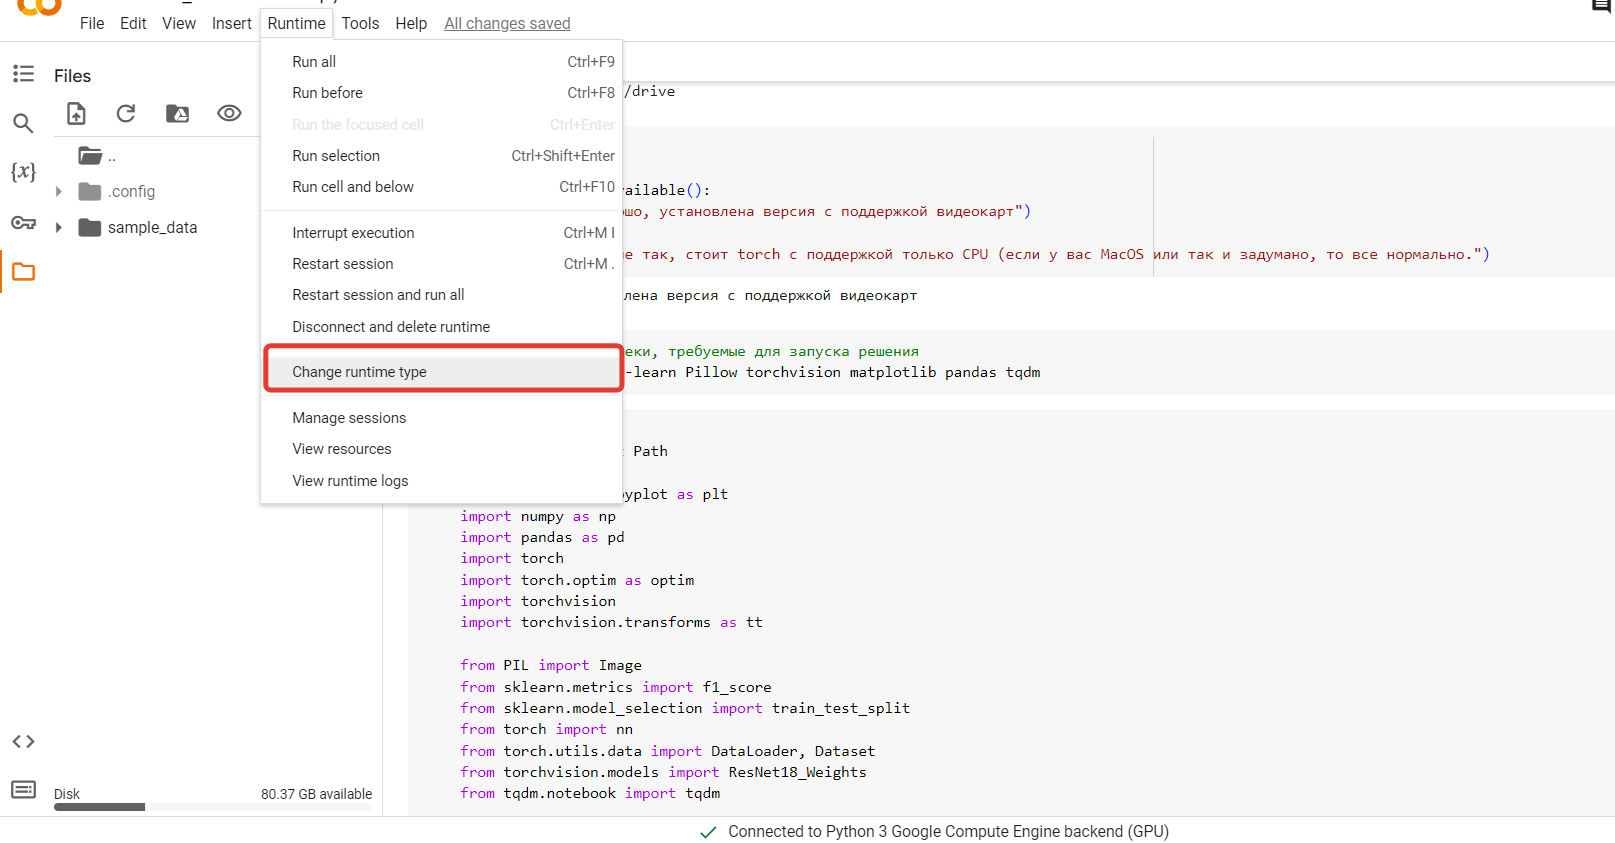
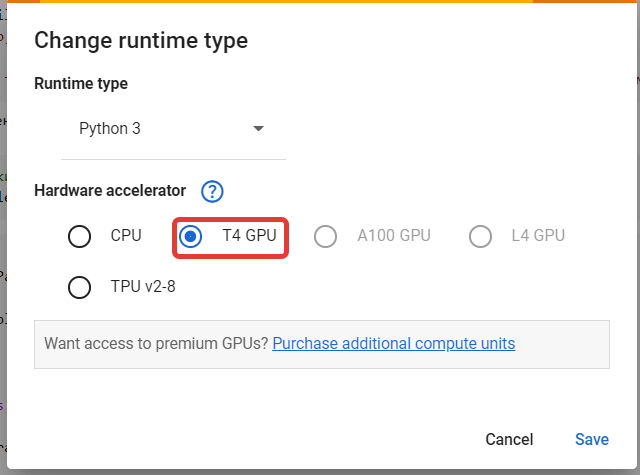

## Установка и импорт библиотек

Прежде, чем приступать к дальнейшим шагам установите [Python](https://www.python.org/downloads/) на компьютер, с которым работаете. Решение проверялось на Python 3.9, но никто не запрещает использовать более новые версии.

Совсем хорошо, если установите отдельное окружение c Python, используя, например [Miniconda](https://docs.anaconda.com/miniconda/) и [jupyter notebook](https://jupyter.org/install).  
После этого можно исполнять команды и код ниже.

Для обучения моделей нам понадобится Pytorch - фреймворк для машинного обучения.  
[Установите его для вашей платформы](https://pytorch.org/get-started/locally/), проверьте, что установлена версия с поддержкой GPU (видеокарт) с помощью кода ниже:

In [1]:
!wget https://storage.yandexcloud.net/ds-ods/files/files/98fd103e/test.zip
!wget https://storage.yandexcloud.net/ds-ods/files/files/389941dc/train.zip
!wget https://storage.yandexcloud.net/ds-ods/files/files/637f87b8/train.csv

--2026-10-22 13:11:11--  https://storage.yandexcloud.net/ds-ods/files/files/98fd103e/test.zip
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 661428517 (631M) [application/x-zip-compressed]
Saving to: ‘test.zip’

test.zip            100%[===================>] 630.79M  67.9MB/s    in 9.9s    

2026-10-22 13:11:21 (63.4 MB/s) - ‘test.zip’ saved [661428517/661428517]

--2026-10-22 13:11:21--  https://storage.yandexcloud.net/ds-ods/files/files/389941dc/train.zip
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1553290492 (1.4G) [application/x-zip-compressed]
Saving to: ‘train.zip’

train.zip       

In [2]:
import os
os.mkdir("data")

In [3]:
! unzip train.zip -d data
! unzip test.zip -d data

Выходные данные были обрезаны до нескольких последних строк (5000).
  inflating: data/test/b2d641d09aadd539e3026f50c81315a7.JPG  
  inflating: data/test/b2dc9b437a4c38b3bad063bd819aa05f.JPG  
  inflating: data/test/b2de9ae53641216f7f8fb6bf1cf13895.JPG  
  inflating: data/test/b2e9c1a49654f469363b952982ed6f4c.JPG  
  inflating: data/test/b2eab2a90b110268e75a305e03bee60e.JPG  
  inflating: data/test/b2eb31f6f8f5db5a6575b959b364e5a1.JPG  
  inflating: data/test/b2f3a5a5e502b6781d3e5c4ab106a78d.JPG  
  inflating: data/test/b2f439e792be6e84237ea1626808cb9c.JPG  
  inflating: data/test/b2f5b7f9c283fcb1de6f1b9f0b88d704.JPG  
  inflating: data/test/b2f8bfeafdbbd80946978e0f337bc12b.JPG  
  inflating: data/test/b2fc4aadd39462ffaa6288038824fdb5.JPG  
  inflating: data/test/b2fc9f1186e6aee94d85f3518ffe1fb3.JPG  
  inflating: data/test/b2fd29cac26a5e74bf5b2bacddaf9782.JPG  
  inflating: data/test/b300c26d6a2491400b5486da55ff312f.JPG  
  inflating: data/test/b304c6092dc655aee07db0310609198a.JPG  
  

In [4]:
import shutil

shutil.copyfile("train.csv", "data/train.csv")

'data/train.csv'

In [5]:
import torch

if torch.cuda.is_available():
    print("Все хорошо, установлена версия с поддержкой видеокарт")
else:
    print("Что-то не так, стоит torch с поддержкой только CPU (если у вас MacOS или так и задумано, то все нормально.")

Все хорошо, установлена версия с поддержкой видеокарт


In [6]:
# Установим библиотеки, требуемые для запуска решения
!pip install scikit-learn Pillow torchvision matplotlib pandas tqdm

In [7]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.optim as optim
import torchvision
import torchvision.transforms as tt

from PIL import Image
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet18_Weights
from tqdm.notebook import tqdm


# Зафиксируем сиды, чтобы обучение было воспроизводимым.
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(1001)

## Подготовка данных для обучения

Распределение классов по всему train.csv:

unified_class
Пятнистый олень        16603
Кабан                   4348
Изюбрь                  2803
Тигр                    2595
Бурый медведь           2093
Ирбис                   1993
Козерог                 1157
Азиатский барсук        1103
Заяц                     963
Волк                     870
Аргали                   824
Лиса                     809
Сурок                    750
Сибирская косуля         691
Рысь                     662
Марал                    475
Гималайский медведь      432
Енотовидная собака       351
Амурский лесной кот      315
Манул                    185
Соболь                   136
Name: count, dtype: int64

Всего классов: 21
Минимум изображений на класс: 136, максимум: 16603
Дисбаланс (max/min): 122.1x


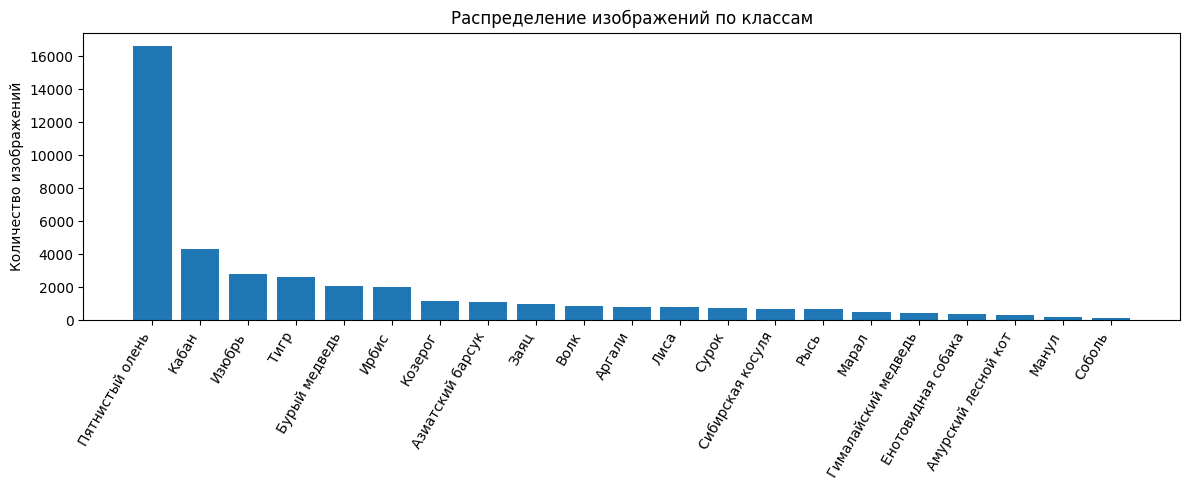

(28110, 3) (12048, 3)

Доли классов в train и val (должны совпадать примерно до десятых долей процента):

                     train_%  val_%
unified_class                      
Азиатский барсук        2.75   2.75
Амурский лесной кот     0.79   0.78
Аргали                  2.05   2.05
Бурый медведь           5.21   5.21
Волк                    2.17   2.17
Гималайский медведь     1.07   1.08
Енотовидная собака      0.88   0.87
Заяц                    2.40   2.40
Изюбрь                  6.98   6.98
Ирбис                   4.96   4.96
Кабан                  10.83  10.82
Козерог                 2.88   2.88
Лиса                    2.01   2.02
Манул                   0.46   0.46
Марал                   1.18   1.19
Пятнистый олень        41.34  41.34
Рысь                    1.65   1.65
Сибирская косуля        1.72   1.72
Соболь                  0.34   0.34
Сурок                   1.87   1.87
Тигр                    6.46   6.47


In [8]:
# Мы подразумеваем, что данные будут лежать в рамках следующей структуры:
# .
# ├── baseline.ipynb
# └── data/
#     ├── train.csv
#     ├── train/
#     │   ├── ***.JPG
#     │   ├── ...
#     │   └── ***.JPG
#     └── test/
#         ├── ***.JPG
#         ├── ...
#         └── ***.JPG


base_path = Path("data/")
data = pd.read_csv(base_path / "train.csv")
images_path = base_path / "train"

# --- Анализ распределения классов ---
class_counts = data["unified_class"].value_counts().sort_values(ascending=False)
print("Распределение классов по всему train.csv:\n")
print(class_counts)
print(f"\nВсего классов: {data['unified_class'].nunique()}")
print(f"Минимум изображений на класс: {class_counts.min()}, максимум: {class_counts.max()}")
print(f"Дисбаланс (max/min): {class_counts.max() / class_counts.min():.1f}x")




In [ ]:
# Столбчатая диаграмма распределения классов
plt.figure(figsize=(12, 5))
plt.bar(class_counts.index, class_counts.values)
plt.xticks(rotation=60, ha='right')
plt.title('Распределение изображений по классам')
plt.ylabel('Количество изображений')
plt.tight_layout()
plt.show()

# Разобъем данные на тренировочную и отложенную (на которой мы будем проверять качество работы) части.
# stratify=y сохраняет пропорции классов в обеих частях — это критично для F1 macro:
# если в валидацию случайно попадёт мало примеров редких классов, оценка качества будет шумной и заниженной.
y = data["class_id"]
train, val = train_test_split(data, test_size=0.3, random_state=1, stratify=y)

train = train.reset_index(drop=True)
val = val.reset_index(drop=True)

print(train.shape, val.shape)

# Проверим, что пропорции классов сохранились
compare = pd.DataFrame({
    "train_%": train["unified_class"].value_counts(normalize=True).round(4) * 100,
    "val_%": val["unified_class"].value_counts(normalize=True).round(4) * 100,
})
print("\nДоли классов в train и val (должны совпадать примерно до десятых долей процента):\n")
print(compare.sort_index())

## Балансировка обучающей выборки

Если классы в данных распределены неравномерно (а в этом датасете это так — от сотен до тысяч изображений на класс), модель получает гораздо больше градиентов от частых классов и выучивает их лучше, а редкие классы игнорирует. Метрика соревнования — F1 macro, которая усредняет F1 по всем классам с равными весами, поэтому провал на редком классе бьёт по итоговому скору так же сильно, как провал на частом.

Существуют два основных подхода:

1. **Undersampling** — случайно отбросить часть изображений доминирующих классов до уровня самого маленького класса. Просто, но теряем данные — часто вредно для нейросетей.
2. **Oversampling через WeightedRandomSampler** — на каждом шаге тренировки каждая картинка класса $c$ выбирается с вероятностью, обратно пропорциональной частоте класса. Эпоха состоит из ~стольки же батчей, как раньше, но редкие классы встречаются в них с той же частотой, что и частные. Данные не теряются, аугментации каждый раз дают новые варианты картинок.

Дополним это **взвешиванием функции потерь** (`weight=...` в CrossEntropyLoss): ошибка на редком классе штрафуется сильнее. Вместе сэмплер и веса потерь — стандартный и надёжный способ борьбы с дисбалансом в PyTorch.

Важно: **валидaционная выборка НЕ балансируется** — она должна отражать реальное распределение данных, иначе оценка качества будет завышена относительно лидерборда.

In [25]:
# --- Балансировка обучающей выборки через WeightedRandomSampler ---
# Вес каждого класса обратно пропорционален его частоте в трейне.
class_counts = train["class_id"].value_counts().sort_index().values  # кол-во объектов каждого класса
class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
# Вес каждого отдельного объекта = вес его класса
sample_weights = class_weights[train["class_id"].values]
# На каждой эпохе будем сэмплировать батчи с заменой: редкие классы попадут в обучение чаще
sampler = torch.utils.data.WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),  # столько же объектов на эпоху, как раньше
    replacement=True
)

print("Веса классов (последние 10):", class_weights[-10:].numpy())

# --- Undersampling (альтернатива): ---
# если хотите убрать дисбаланс отбрасыванием объектов частых классов, раскомментируйте блок ниже
# и не используйте sampler.
# min_count = train["class_id"].value_counts().min()
# train = (train.groupby("class_id", group_keys=False)
#              .apply(lambda x: x.sample(min_count, random_state=1))
#              .sample(frac=1, random_state=1)
#              .reset_index(drop=True))


tensor([6.8259e-04, 3.3113e-03, 3.2852e-04, 5.0968e-04, 8.6044e-05, 3.0120e-03,
        2.0661e-03, 1.2953e-03, 1.0526e-02, 4.5249e-03, 7.6923e-03, 2.1598e-03,
        5.5066e-04, 7.1685e-04, 1.7331e-03, 1.2346e-03, 1.6420e-03, 1.7668e-03,
        4.0650e-03, 1.4837e-03, 1.9048e-03])
tensor([5.5066e-04, 3.3113e-03, 8.6044e-05,  ..., 5.5066e-04, 8.6044e-05,
        8.6044e-05])
Веса классов (последние 10): [0.00215983 0.00055066 0.00071685 0.0017331  0.00123457 0.00164204
 0.00176678 0.00406504 0.00148368 0.00190476]


In [10]:
# Что значат колонки:
# unified_class - имя класса кириллицей
# class_id - численный идентификатор класса для удобства работы
# image_name - название файла изобаржения в папке train.

data.head()

,unified_class,class_id,image_name
0,Кабан,2,0fa5f1cd824ca3705b654ada33437337.JPG
1,Изюбрь,3,da2969de9de9ca78eee5ba249e52ce89.JPG
2,Пятнистый олень,4,5b5d9c79cec42ea630d9f29ae59d2d6d.JPG
3,Рысь,11,e5dfc9f687530959332a2f8aa0594140.JPG
4,Сибирская косуля,6,50de65ad44e8dc71ed7f122eff3f2164.JPG


## Инициализация нужных объектов и обучение базовой модели

Обучать модель с нуля очень тяжело - требуется много данных, много времени на обучение. И именно поэтому выгодно использовать предварительно обученные модели. Они позволяют дообучать модель под конкретную задачу. [Здесь](https://pytorch.org/vision/stable/models.html#classification) список предобученных моделей и весов. В качестве улучшения результатов классификации можно поменять веса модели и\или другую модель.

 В качестве стартовой модели возьмем ResNet18, предобученный на датасете ImageNet1K
 Но поменяем количество предсказываемых классов, так как вместо тысячи у нас десять классов.
 Можно было бы взять модель побольше и получить результаты лучше, но сейчас ограничимся ResNet18.

In [11]:
class ResNet18(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        # Инициализируем модель
        self.model = torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        # Подменим классификационный слой на наш собственный
        self.model.fc = torch.nn.Linear(self.model.fc.in_features, num_classes)

    def forward(self, batch):
        inputs, _ = batch
        return self.model(inputs)

```
for name, param in model.named_parameters():
    if "fc" in name:  # Если параметр относится к fc
        param.requires_grad = True
    else:
        param.requires_grad = False
```

Теперь подготовим класс датасет, в котором укажем насколько он большой (метод `__len__`) и как нам получить один элемент датасета (пару картинка с классом, которому эта картинка соответствует) - метод `__getitem__`.

Обращу внимание на transforms (они же аугментации) - способ, позволящий искусственно расширить датасет за счет того, что мы, обращаясь к датасету, каждый раз немного изменяем изображение разными способами (делаем из цветного черно-белое, вырезаем часть изображения, поворачиваем вокруг оси и т.д.). Часто это позволяет обучить модель более высокого качества, а так же сделать её устойчивее к непривычным ей данным.

In [12]:
class AnimalsDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, path_to_images: Path, transforms: tt.Compose) -> None:
        self.df = dataframe
        self.path_to_images = path_to_images
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(self.path_to_images / row["image_name"]).convert('RGB')
        if self.transforms is not None:
            image = self.transforms(image)
        return image, row["class_id"]

[Здесь список transform](https://pytorch.org/vision/stable/transforms.html#v1-api-reference) для создание аугментациий, которые могут помочь в обучение модели с более высокой метрикой.

In [13]:
from torchvision.utils import make_grid
from torchvision.io import decode_image
from pathlib import Path
import torchvision.transforms.functional as F

def show(imgs):
    if not isinstance(imgs, list):
        imgs = [imgs]
    fig, axs = plt.subplots(ncols=len(imgs), squeeze=False)
    for i, img in enumerate(imgs):
        img = img.detach()
        img = F.to_pil_image(img)
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])


In [14]:
from torchvision.io import read_image
idx = 1
img = read_image(images_path / data.iloc[idx]["image_name"])

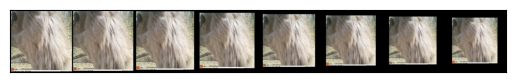

In [15]:
def visualization_padding(img, padding_list, size):
  img_padded = []
  for padding in padding_list:
    transform = tt.Compose([
        tt.Pad(padding),
        tt.Resize(size)
    ])
    img_padded.append(transform(img))
  return img_padded

padding_list=[0, 5, 15, 30, 45, 60, 75, 90]
img_list = visualization_padding(img, padding_list, 224)
grid = make_grid(img_list)
show(grid)

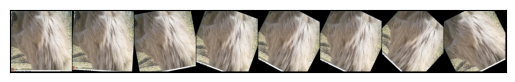

In [16]:
def visualization_rotation(img, rotation_list, size):
  img_rotated = []
  for rotation in rotation_list:
    transform = tt.Compose([
        tt.RandomRotation(rotation),
        tt.Resize(size)
    ])
    img_rotated.append(transform(img))
  return img_rotated

rotation_list=[0, 5, 15, 30, 45, 60, 75, 90]
img_list = visualization_rotation(img, rotation_list, 224)
grid = make_grid(img_list)
show(grid)

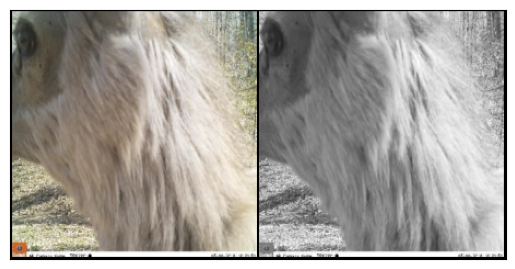

In [17]:
def visualization_grayscale(img, size):
  transform_grey = tt.Compose([
        tt.Grayscale(3),
        tt.Resize(size)
    ])
  transform_resize = tt.Compose([
        tt.Resize(size)
    ])
  imgs = [transform_resize(img), transform_grey(img)]
  return imgs

img_list = visualization_grayscale(img, 224)
grid = make_grid(img_list)
show(grid)

## Аугментации обучающей выборки

Для классификации сложноразличимых видов животных добавим **умеренные** аугментации только к обучающей выборке. Они создают новые варианты исходных фотографий и снижают запоминание данных. Это особенно важно при использовании `WeightedRandomSampler`: изображения редких классов попадают в обучение повторно, а случайные преобразования делают такие повторы менее похожими друг на друга.

- **`RandomResizedCrop`** — случайно меняет масштаб и положение животного в кадре. Модель становится устойчивее к тому, что объект занимает разную часть изображения. Нижняя граница `scale=0.7` не даёт обрезать кадр слишком сильно, когда на нём могут потеряться важные признаки вида.
- **`RandomHorizontalFlip`** — отражение слева направо обычно не меняет вид животного, поэтому это безопасный способ увеличить разнообразие ракурсов.
- **`RandomRotation(±10°)`** — имитирует небольшой наклон камеры. Большие повороты не используем: они создают менее естественные фотографии и обширные пустые области по краям.
- **`ColorJitter`** — небольшие изменения яркости, контраста и насыщенности помогают учитывать разное освещение и настройки камеры. Изменение оттенка (`hue`) намеренно очень маленькое: окрас может быть важным признаком для различения близких видов. Вероятность `p=0.8` оставляет часть изображений без цветового сдвига.
- **`RandomErasing`** — с вероятностью 25% скрывает небольшую случайную область, имитируя частичное перекрытие животного ветками, травой или другими объектами. Благодаря этому модель меньше полагается на одну локальную деталь.

**Валидационные изображения не аугментируются:** для них остаются только детерминированные `Resize`, `ToTensor` и `Normalize`. Иначе оценка качества стала бы случайной и была бы несопоставима между запусками. Нормализация в обоих пайплайнах одинаковая и соответствует предобученным весам ImageNet.

Не добавляем вертикальные отражения, перевод в оттенки серого, сильные повороты и агрессивные цветовые искажения: для этой задачи они с большей вероятностью разрушат полезные признаки, чем принесут пользу. Предложенные параметры — хорошая стартовая точка; итоговую силу аугментаций следует выбирать по F1 macro на фиксированной валидационной выборке.


In [ ]:
# Случайные аугментации применяем ТОЛЬКО к train.
# Параметры умеренные, чтобы сохранить форму и окрас — важные признаки близких видов животных.
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = tt.Compose([
    # Меняем масштаб и композицию, но не обрезаем слишком большую часть кадра.
    tt.RandomResizedCrop(224, scale=(0.7, 1.0), ratio=(0.8, 1.25)),
    # Горизонтальное отражение не меняет класс животного.
    tt.RandomHorizontalFlip(p=0.5),
    # Небольшой наклон камеры без экстремальных поворотов.
    tt.RandomRotation(degrees=10),
    # Умеренная вариация освещения и цвета; hue оставляем почти неизменным.
    tt.RandomApply([
        tt.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03)
    ], p=0.8),
    tt.ToTensor(),
    tt.Normalize(mean=imagenet_mean, std=imagenet_std),
    # RandomErasing работает с тензором, поэтому стоит после ToTensor и Normalize.
    tt.RandomErasing(p=0.25, scale=(0.02, 0.15), ratio=(0.3, 3.3), value="random"),
])

# На валидации случайных преобразований нет: результат должен быть воспроизводимым.
val_transform = tt.Compose([
    tt.Resize((224, 224)),
    tt.ToTensor(),
    tt.Normalize(mean=imagenet_mean, std=imagenet_std),
])

train_dataset = AnimalsDataset(train, images_path, transforms=train_transform)
val_dataset = AnimalsDataset(val, images_path, transforms=val_transform)

# WeightedRandomSampler одновременно перемешивает и балансирует обучающую выборку,
# поэтому для train DataLoader параметр shuffle не нужен.
train_dataloader = DataLoader(
    train_dataset, batch_size=32, num_workers=0, sampler=sampler
)
valid_dataloader = DataLoader(
    val_dataset, batch_size=32, num_workers=0, shuffle=False
)


In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Для обучения выбран девайс {}".format(device))

Для обучения выбран девайс cuda


[По этой ссылка](https://pytorch.org/docs/stable/optim.

---

html#algorithms) можно узнать больше об оптимизаторах для задачи классификации.

[По этой ссылке](https://pytorch.org/docs/stable/nn.html#loss-functions) можно узнать больше о функциях потерь для классификации.

[По этой ссылке](https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate) режимы рассписаний

In [20]:
# Напишем код для обучения нашей нейронной сети:
model = ResNet18(num_classes=data["unified_class"].nunique()).to(device)

# Инициализируем функцию потерь (loss/criterion), а так же оптимизатор, который будет регулировать обновление весов нашей модели
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))  # редкие классы штрафуются сильнее

# Переменные для визуализации метрик и функции потерь
train_losses = []
val_losses = []
# Для удобства оценивать качество модели будем той же метрику, что на лидерборде - F1 score
train_f1_scores = []
val_f1_scores = []

best_val_f1 = 0.0
best_model_path = 'best_model.pth'

# Определим, сколько раз мы пройдёмся по всему датасету, прежде, чем закончим обучение модели и выберем лучшую версию
num_epochs = 10

# Шаговое уменьшение (StepLR)
# scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  # Каждые 5 эпох уменьшать lr в 10 раз

# Напишем свой train_loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    train_true = []
    train_pred = []

    for batch in tqdm(train_dataloader):
        inputs, labels = batch
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model((inputs, labels))
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)
        train_true.extend(labels.cpu().numpy())
        train_pred.extend(preds.cpu().numpy())

    train_f1 = f1_score(train_true, train_pred, average='macro')
    train_losses.append(running_loss / len(train_dataloader))
    train_f1_scores.append(train_f1)

    # scheduler.step()
    model.eval()
    val_running_loss = 0.0
    val_true = []
    val_pred = []

    # валидационный цикл, когда мы оцениваем качество работы модели на отложенной выборке
    with torch.no_grad():
        for batch in tqdm(valid_dataloader):
            inputs, labels = batch
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model((inputs, labels))
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_f1 = f1_score(val_true, val_pred, average='macro')
    val_losses.append(val_running_loss / len(valid_dataloader))
    val_f1_scores.append(val_f1)

    # если получившаяся модель лучше предыдущей, сохраним чекпоинт
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_model_path)
        print(f'New best model saved with F1: {best_val_f1:.4f}')


    # выведем в консоль получившиеся результаты на отдельной эпохе
    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_losses[-1]:.4f}, Train F1: {train_f1:.4f}, '
          f'Val Loss: {val_losses[-1]:.4f}, Val F1: {val_f1:.4f}')


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 120MB/s]


  0%|          | 0/879 [00:00<?, ?it/s]

  0%|          | 0/377 [00:00<?, ?it/s]

New best model saved with F1: 0.3422
Epoch [1/10], Train Loss: 1.1637, Train F1: 0.4211, Val Loss: 1.7325, Val F1: 0.3422


...

  0%|          | 0/377 [00:00<?, ?it/s]

Epoch [9/10], Train Loss: 0.0572, Train F1: 0.9049, Val Loss: 0.9079, Val F1: 0.6484


  0%|          | 0/879 [00:00<?, ?it/s]

  0%|          | 0/377 [00:00<?, ?it/s]

Epoch [10/10], Train Loss: 0.0485, Train F1: 0.9183, Val Loss: 1.2327, Val F1: 0.5825


Задача. Найти распределение классов. Построить столбчатую диаграмму(по возможности
)  есть ли картинки с несколькими животными

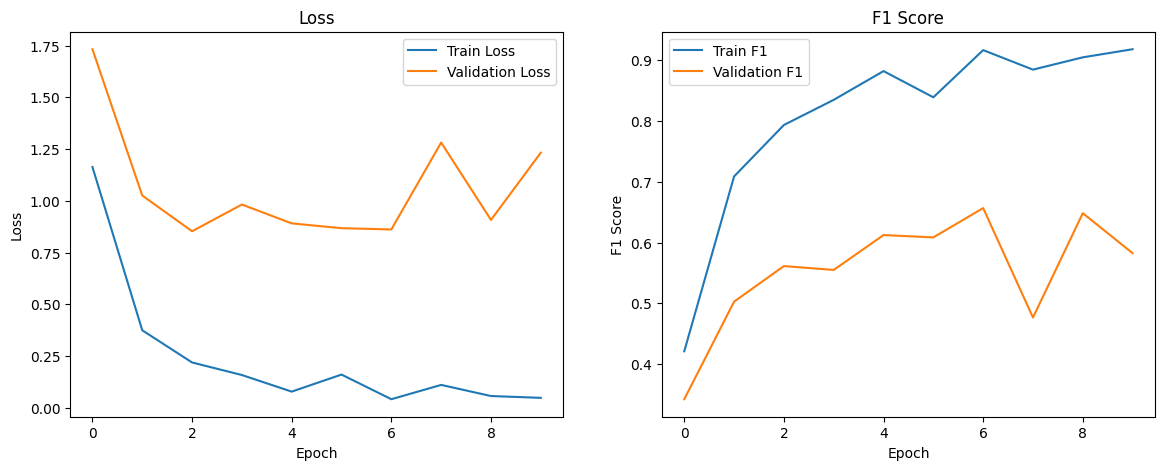

In [21]:
# После эксперимента важно оценить полученные кривые обучения, чтобы сформировать новые гипотезы
# Визуализируем их!

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_f1_scores, label='Train F1')
plt.plot(val_f1_scores, label='Validation F1')
plt.title('F1 Score')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()

plt.show()

## Инференс модели и формирование сабмита

In [22]:
# У нас есть обученная модель! Теперь сделаем инференс модели на тестовых данных и подготовим файл сабмита!

# Немного перепишем наш датасет, ведь для тестовой части у нас нет меток классов, но нам нужны имена файлов для сабмита
class InferenceDataset(Dataset):
    def __init__(self, image_paths, transforms=None):
        self.image_paths = image_paths
        self.transforms = transforms

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')
        if self.transforms is not None:
            image = self.transforms(image)
        return image, image_path.name


# Тут важно не ошибиться и не использовать тренировочные трансформы
infer_transform = tt.Compose([
    tt.Resize((224, 224)),
    tt.ToTensor(),
    tt.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Найдем все тестовые картинки
test_image_paths = base_path / "test"
test_image_paths = list(test_image_paths.glob("*.JPG"))

infer_dataset = InferenceDataset(test_image_paths, transforms=infer_transform)
infer_dataloader = DataLoader(infer_dataset, batch_size=64, shuffle=False)

# Инициализируем нашу модель и загрузим в неё лучшие после эксперимента веса
model = ResNet18(num_classes=data["unified_class"].nunique()).to(device)
model.load_state_dict(torch.load(best_model_path))
# Не забудем перевести модель в режим предсказания, а не обучения.
model.eval()

# Для ускорения инференса будем подавать в модель картинки батчами (по несколько картинок за раз) и сохраним предсказанные метки классов.
results = []
for images, image_names in tqdm(infer_dataloader):
    images = images.to(device)

    with torch.no_grad():
        outputs = model((images, None))
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

    for image_name, pred_class in zip(image_names, preds):
        results.append({"image_name": image_name, "predicted_class": pred_class})



# Для удобства объединим все пары "имя файла - предсказанный класс" в датафрейм (таблицу) с колонками image_name, predicted_class
df_results = pd.DataFrame(results)

# Вывод DataFrame
print(df_results.head())

  0%|          | 0/256 [00:00<?, ?it/s]

                             image_name  predicted_class
0  4229aa5d1dfc7d3e40dd4f08718d3b35.JPG                2
1  bcc57c5ef4ed228538c07942d9bcd8a5.JPG               16
2  a12002dc2cbcd6b6898019c233a94125.JPG                3
3  da0e3f68514fe172479a2fd6d116c782.JPG                3
4  1bfd7f20e80506c53e7729436ffee29f.JPG                2


In [ ]:
# Сохраним результат предсказаний в файл и всё! Можно отправлять!
df_results.to_csv("submission.csv", index=False)

Улучшение модели с помощью голосования
```
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
import torch.nn.functional as F

# Предположим, у нас есть две модели обученные для классификации
model1, model2

# Функция для объединения моделей
def ensemble_predict(models, inputs):
    predictions = []
    for model in models:
        model.eval()  # Переключение модели в режим оценки
        with torch.no_grad():
            outputs = F.softmax(model(inputs), dim=1)
            predictions.append(outputs)
    
    # Усреднение вероятностей (Soft Voting)
    avg_predictions = torch.mean(torch.stack(predictions), dim=0)
    return avg_predictions

# Пример использования
models = [model1, model2]
inputs   # Пример входного изображения
ensemble_output = ensemble_predict(models, inputs)
predicted_class = torch.argmax(ensemble_output, dim=1)
print(f"Predicted class: {predicted_class.item()}")

```